# Прогнозирование площади лесных пожаров

**Тип задачи:** регрессия; дополнительно исследуется двухэтапный подход «произойдёт ли возгорание → какова площадь выгорания».

Цель проекта — исследовать данные о лесных пожарах в природном парке Монтезинью (Португалия), изучить распределения и взаимосвязи признаков, попробовать разные способы подготовки данных и сравнить модели машинного обучения.

> **Источник данных:** [UCI Machine Learning Repository — Forest Fires](https://archive.ics.uci.edu/dataset/162/forest%2B%C2%ADfires). В наборе 517 наблюдений; целевая переменная `area` — площадь выгоревшей территории в гектарах.

## Как устроено исследование и как читать выводы

Цель — предсказать `area` (площадь пожара) в гектарах. Главная особенность данных — **47,8% нулевых значений и длинный правый хвост**. 

В ноутбуке \(R^2\) используется как основной критерий сравнения, потому что цель — выяснить, удаётся ли объяснить вариацию целевой переменной. MAE и RMSE обязательно дополняют \(R^2\). Для бинарного первого этапа двухэтапной модели используются Precision, Recall и F1.

## Содержание

1. Загрузка данных
2. Разведочный анализ (EDA)
3. Подготовка и преобразование признаков
4. Дополнительные эксперименты: PCA и DBSCAN
5. Сравнение регрессионных моделей
6. Двухэтапная модель: классификация и регрессия
7. Итоги и ограничения


## 1. Загрузка данных

In [1]:
from pathlib import Path
from IPython.display import display
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, ExtraTreesRegressor
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    f1_score,
    precision_score,
    recall_score,
)

try:
    import lightgbm as lgb
except Exception as exc:
    lgb = None
    print(f'LightGBM недоступен; соответствующие эксперименты будут пропущены: {exc}')

try:
    import xgboost as xgb
except Exception as exc:
    xgb = None
    print(f'XGBoost недоступен; соответствующие эксперименты будут пропущены: {exc}')

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid')

RANDOM_STATE = 42
pd.set_option('display.max_columns', None)

In [2]:
dataset = pd.read_csv('forestfires.csv')

required_columns = {
    'X', 'Y', 'month', 'day', 'FFMC', 'DMC', 'DC', 'ISI',
    'temp', 'RH', 'wind', 'rain', 'area'
}
missing_columns = required_columns.difference(dataset.columns)
if missing_columns:
    raise ValueError(f'В CSV отсутствуют ожидаемые столбцы: {sorted(missing_columns)}')

print(f'Размер датасета: {dataset.shape[0]} строк × {dataset.shape[1]} столбцов')
dataset.head()

Размер датасета: 517 строк × 13 столбцов


,X,Y,month,day,FFMC,DMC,DC,ISI,temp,RH,wind,rain,area
0,7,5,mar,fri,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,0.0
1,7,4,oct,tue,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,0.0
2,7,4,oct,sat,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,0.0
3,8,6,mar,fri,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,0.0
4,8,6,mar,sun,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,0.0


In [3]:
print('Типы данных и пропуски:')
dataset.info()

print('\nКоличество пропусков по столбцам:')
display(dataset.isna().sum().sort_values(ascending=False).to_frame('Пропуски'))

print('\nОписательная статистика числовых признаков:')
display(dataset.describe().T)

Типы данных и пропуски:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       517 non-null    int64  
 1   Y       517 non-null    int64  
 2   month   517 non-null    object 
 3   day     517 non-null    object 
 4   FFMC    517 non-null    float64
 5   DMC     517 non-null    float64
 6   DC      517 non-null    float64
 7   ISI     517 non-null    float64
 8   temp    517 non-null    float64
 9   RH      517 non-null    int64  
 10  wind    517 non-null    float64
 11  rain    517 non-null    float64
 12  area    517 non-null    float64
dtypes: float64(8), int64(3), object(2)
memory usage: 52.6+ KB

Количество пропусков по столбцам:


,Пропуски
X,0
Y,0
month,0
day,0
FFMC,0
DMC,0
DC,0
ISI,0
temp,0
RH,0



Описательная статистика числовых признаков:


,count,mean,std,min,25%,50%,75%,max
X,517.0,4.669246,2.313778,1.0,3.0,4.00,7.00,9.00
Y,517.0,4.299807,1.229900,2.0,4.0,4.00,5.00,9.00
FFMC,517.0,90.644681,5.520111,18.7,90.2,91.60,92.90,96.20
DMC,517.0,110.872340,64.046482,1.1,68.6,108.30,142.40,291.30
DC,517.0,547.940039,248.066192,7.9,437.7,664.20,713.90,860.60
ISI,517.0,9.021663,4.559477,0.0,6.5,8.40,10.80,56.10
temp,517.0,18.889168,5.806625,2.2,15.5,19.30,22.80,33.30
RH,517.0,44.288201,16.317469,15.0,33.0,42.00,53.00,100.00
wind,517.0,4.017602,1.791653,0.4,2.7,4.00,4.90,9.40
rain,517.0,0.021663,0.295959,0.0,0.0,0.00,0.00,6.40


### Что описывают признаки

- `X`, `Y` — пространственные координаты на карте парка.
- `month`, `day` — месяц и день недели.
- `FFMC`, `DMC`, `DC`, `ISI` — индексы системы Fire Weather Index, характеризующие условия горения и распространения огня.
- `temp`, `RH`, `wind`, `rain` — температура, относительная влажность, скорость ветра и осадки.
- `area` — площадь выгоревшей территории в гектарах (**целевая переменная**).

## 2. Разведочный анализ данных (EDA)

### 2.1. Распределение целевой переменной

В исходном исследовании заметная часть значений `area` равна нулю, а распределение имеет длинный правый хвост. Это затрудняет обучение обычных регрессионных моделей: редкие крупные значения сильно отличаются от типичных наблюдений.

Наблюдений с area = 0: 247 из 517 (47.8%)
Медиана area: 0.520 га
Максимальная area: 1090.840 га


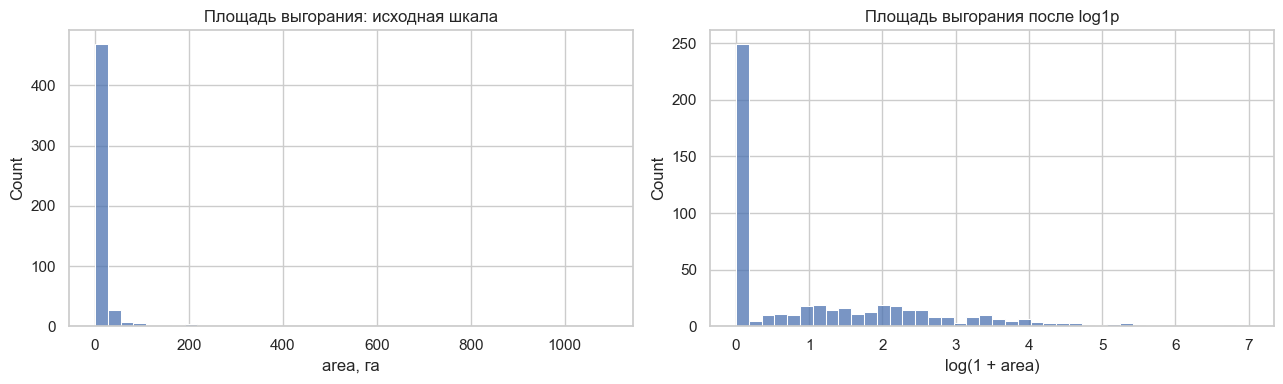

In [4]:
zero_count = int((dataset['area'] == 0).sum())
zero_share = 100 * zero_count / len(dataset)

print(f'Наблюдений с area = 0: {zero_count} из {len(dataset)} ({zero_share:.1f}%)')
print(f"Медиана area: {dataset['area'].median():.3f} га")
print(f"Максимальная area: {dataset['area'].max():.3f} га")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(dataset['area'], bins=40, color='C0', ax=axes[0])
axes[0].set_title('Площадь выгорания: исходная шкала')
axes[0].set_xlabel('area, га')

sns.histplot(np.log1p(dataset['area']), bins=40, color='C0', ax=axes[1])
axes[1].set_title('Площадь выгорания после log1p')
axes[1].set_xlabel('log(1 + area)')
plt.tight_layout()
plt.show()

### Что говорит распределение `area`

Получено **247 нулевых значений из 517 (47,8%)**, медиана `0,52` га и максимум `1 090,84` га. Среднее — около `12,85` га, то есть приблизительно в 24,7 раза выше медианы. Это значит, что почти половина наблюдений равна нулю, а небольшое число крупных пожаров формирует длинный правый хвост.

Отсюда следуют последствия:

1. Модель, которая хорошо описывает малые площади, которые, очевидно, по количеству данных преобладают, может ошибаться на редких крупных пожарах. И наоборот, подгонка под экстремумы может ухудшить прогноз для большинства небольших случаев.
2. Напрашивается замена целевой переменной: `log(area + 1)`. Она сжимает длинный хвост и сохраняет нули (`log(1) = 0`). 


### 2.2. Временные признаки и числовые переменные

Сравним количество наблюдений по месяцам и дням недели, а также посмотрим, как числовые признаки соотносятся с площадью выгорания.

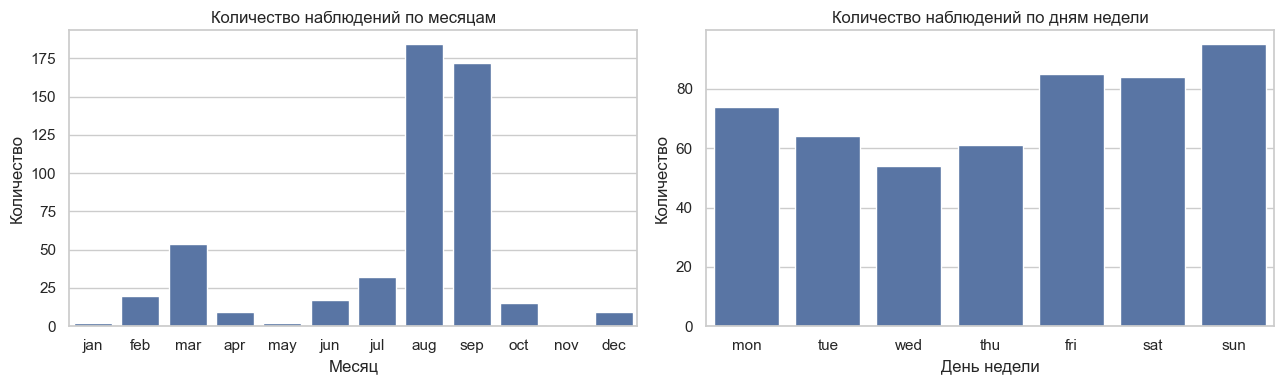

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
month_order = ['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
day_order = ['mon', 'tue', 'wed', 'thu', 'fri', 'sat', 'sun']

sns.countplot(data=dataset, x='month', order=month_order, color='C0', ax=axes[0])
axes[0].set_title('Количество наблюдений по месяцам')
axes[0].set_xlabel('Месяц')
axes[0].set_ylabel('Количество')

sns.countplot(data=dataset, x='day', order=day_order, color='C0', ax=axes[1])
axes[1].set_title('Количество наблюдений по дням недели')
axes[1].set_xlabel('День недели')
axes[1].set_ylabel('Количество')
plt.tight_layout()
plt.show()

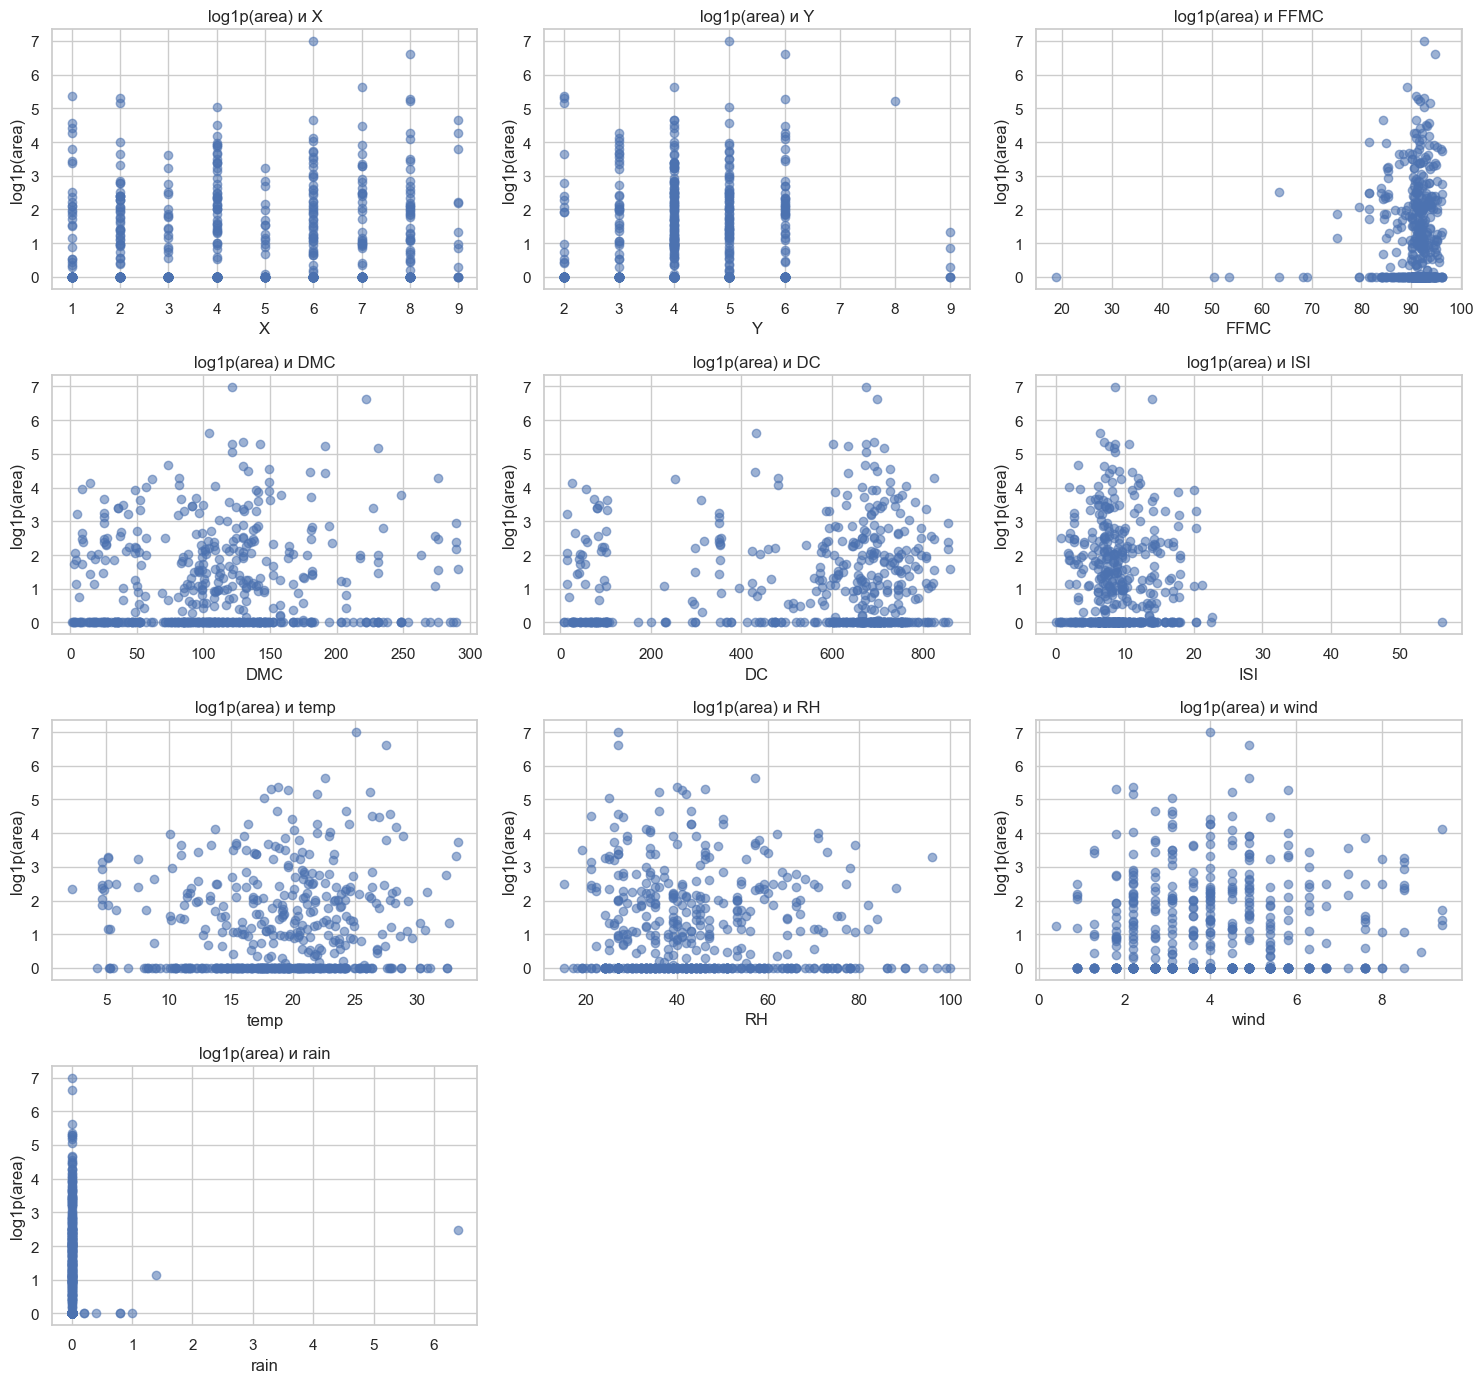

In [6]:
numeric_features = [col for col in dataset.select_dtypes(include=np.number).columns if col != 'area']
n_cols = 3
n_rows = int(np.ceil(len(numeric_features) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.5 * n_rows))
axes = np.asarray(axes).reshape(-1)

for ax, col in zip(axes, numeric_features):
    ax.scatter(dataset[col], np.log1p(dataset['area']), alpha=0.55)
    ax.set_xlabel(col)
    ax.set_ylabel('log1p(area)')
    ax.set_title(f'log1p(area) и {col}')

for ax in axes[len(numeric_features):]:
    ax.remove()

plt.tight_layout()
plt.show()

### Интерпретация диаграмм рассеяния

На исходной шкале (просто area, до преобразования) большинство наблюдений сжимается около нуля, из-за чего линейный тренд трудно увидеть. На log1p(area) шкале лучше, но линейный тренд не прослеживается.


### 2.3. Проверка экстремальных значений

Возникает идея рассматривать фильтр `area <= 300` и `rain <= 3`. 

,Условие,Количество наблюдений,"Доля, %"
0,area > 300 га,2,0.386847
1,rain > 3,1,0.193424


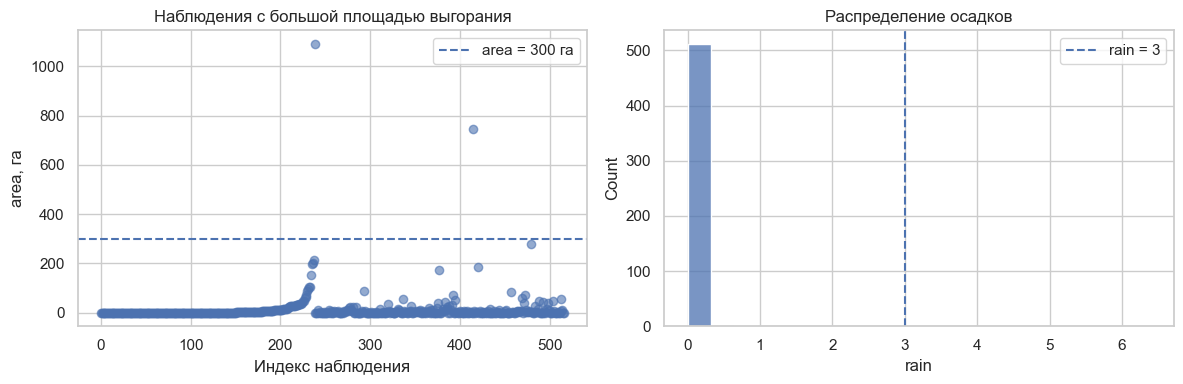

In [7]:
filter_check = pd.DataFrame({
    'Условие': ['area > 300 га', 'rain > 3'],
    'Количество наблюдений': [
        int((dataset['area'] > 300).sum()),
        int((dataset['rain'] > 3).sum()),
    ],
})
filter_check['Доля, %'] = 100 * filter_check['Количество наблюдений'] / len(dataset)
display(filter_check)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(dataset.index, dataset['area'], alpha=0.6)
axes[0].axhline(300, linestyle='--', label='area = 300 га')
axes[0].set_title('Наблюдения с большой площадью выгорания')
axes[0].set_xlabel('Индекс наблюдения')
axes[0].set_ylabel('area, га')
axes[0].legend()

sns.histplot(dataset['rain'], bins=20, color='C0', ax=axes[1])
axes[1].axvline(3, linestyle='--', label='rain = 3')
axes[1].set_title('Распределение осадков')
axes[1].set_xlabel('rain')
axes[1].legend()
plt.tight_layout()
plt.show()

### Почему экстремальные значения не удаляются автоматически

Фильтр `area > 300` затрагивает всего **2 строки (0,39%)**, а `rain > 3` — **1 строку (0,19%)**. Но малое количество не доказывает, что это ошибки. Крупные площади — реальные пожары и наша модель должна их прогнозировать.

## 3. Подготовка и преобразование признаков

Месяц и день недели циклически упорядочены: декабрь близок к январю, а воскресенье — к понедельнику. Поэтому вместо произвольного числового расстояния между категориями добавим синус и косинус соответствующего угла.

Для месяца используется период 12, для дня недели — период 7. 

In [8]:
month_map = {
    'jan': 1, 'feb': 2, 'mar': 3, 'apr': 4, 'may': 5, 'jun': 6,
    'jul': 7, 'aug': 8, 'sep': 9, 'oct': 10, 'nov': 11, 'dec': 12,
}
day_map = {'mon': 1, 'tue': 2, 'wed': 3, 'thu': 4, 'fri': 5, 'sat': 6, 'sun': 7}

X = dataset.drop(columns='area').copy()
X['month_num'] = X['month'].map(month_map)
X['day_num'] = X['day'].map(day_map)

if X[['month_num', 'day_num']].isna().any().any():
    raise ValueError('В month или day найдены значения, отсутствующие в словарях кодирования.')

X['month_sin'] = np.sin(2 * np.pi * X['month_num'] / 12)
X['month_cos'] = np.cos(2 * np.pi * X['month_num'] / 12)
X['day_sin'] = np.sin(2 * np.pi * X['day_num'] / 7)
X['day_cos'] = np.cos(2 * np.pi * X['day_num'] / 7)
X = X.drop(columns=['month', 'day', 'month_num', 'day_num'])
y = dataset['area'].astype(float).copy()

print(f'Число признаков после кодирования: {X.shape[1]}')
display(X.head())

Число признаков после кодирования: 14


,X,Y,FFMC,DMC,DC,ISI,temp,RH,wind,rain,month_sin,month_cos,day_sin,day_cos
0,7,5,86.2,26.2,94.3,5.1,8.2,51,6.7,0.0,1.000000,6.123234e-17,-9.749279e-01,-0.222521
1,7,4,90.6,35.4,669.1,6.7,18.0,33,0.9,0.0,-0.866025,5.000000e-01,9.749279e-01,-0.222521
2,7,4,90.6,43.7,686.9,6.7,14.6,33,1.3,0.0,-0.866025,5.000000e-01,-7.818315e-01,0.623490
3,8,6,91.7,33.3,77.5,9.0,8.3,97,4.0,0.2,1.000000,6.123234e-17,-9.749279e-01,-0.222521
4,8,6,89.3,51.3,102.2,9.6,11.4,99,1.8,0.0,1.000000,6.123234e-17,-2.449294e-16,1.000000


### Корреляционный анализ



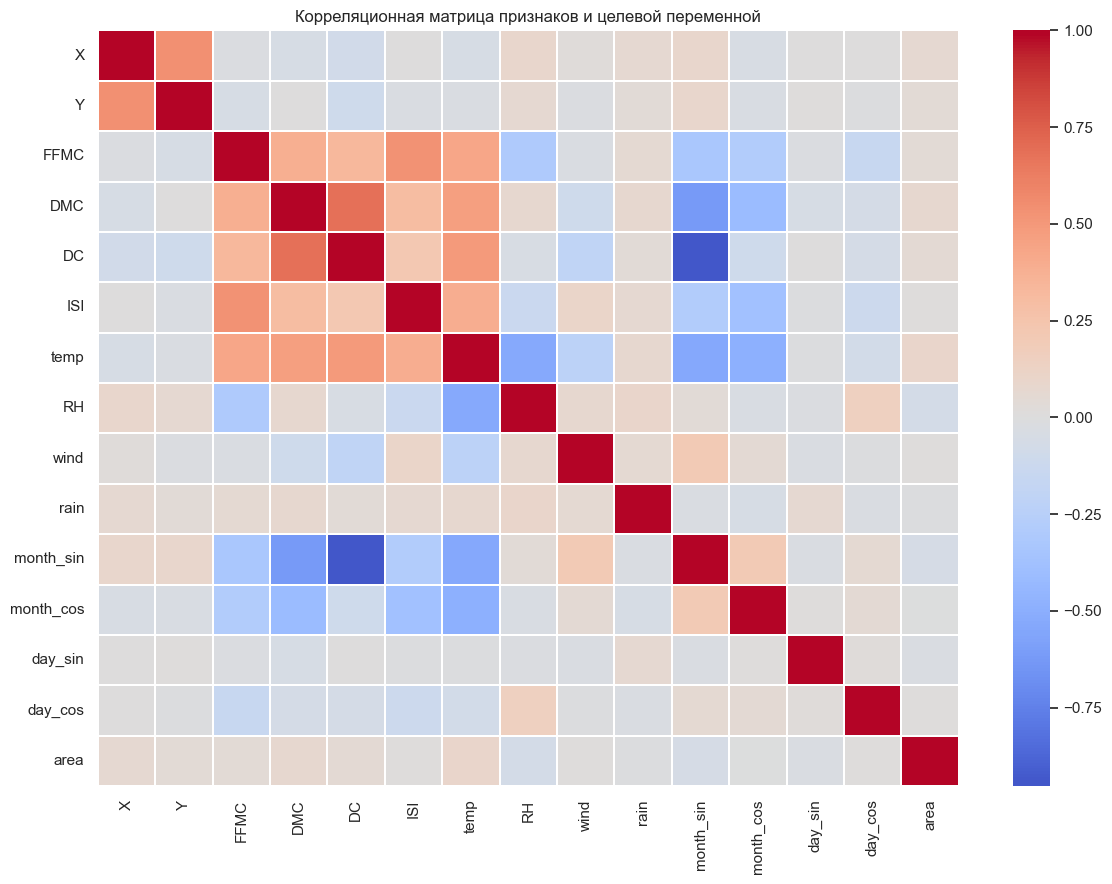

,Корреляция с area
RH,-0.075519
month_sin,-0.059179
day_sin,-0.023773
rain,-0.007366
month_cos,-0.001847
ISI,0.008258
wind,0.012317
day_cos,0.013526
FFMC,0.040122
Y,0.044873


In [9]:
corr_data = X.copy()
corr_data['area'] = y
corr_matrix = corr_data.corr(numeric_only=True)

plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, cmap='coolwarm', center=0, linewidths=0.25)
plt.title('Корреляционная матрица признаков и целевой переменной')
plt.tight_layout()
plt.show()

area_correlations = corr_matrix['area'].drop('area').sort_values()
display(area_correlations.to_frame('Корреляция с area'))

### Выводы из корреляционной матрицы

Максимальная по модулю корреляция Пирсона с `area` — у `temp` (около **0,098**), затем `DMC` (0,073), `X` (0,063), а у `RH` она отрицательная (−0,076). Все значения малы по модулю; сильной **линейной парной** связи с площадью здесь не видно.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f'Обучающая выборка: {X_train.shape}')
print(f'Тестовая выборка:  {X_test.shape}')
print(f'Доля area = 0 в train: {(y_train == 0).mean():.1%}')
print(f'Доля area = 0 в test:  {(y_test == 0).mean():.1%}')

scaler_for_exploration = StandardScaler()
X_train_scaled = scaler_for_exploration.fit_transform(X_train)

Обучающая выборка: (413, 14)
Тестовая выборка:  (104, 14)
Доля area = 0 в train: 47.5%
Доля area = 0 в test:  49.0%


### Почему выбрано такое разбиение

Разбиение 80/20 оставляет 413 строк для обучения и 104 для test. В train доля нулевой площади составляет 47,5%, а в test — 49%; состав по `area == 0` похож.


## 4. PCA и DBSCAN

Эти методы используются как экспериментальные. Хотелось бы снизить размерность признаков с помощью PCA и обнаружить кластерную структуру с использованием DBSCAN.

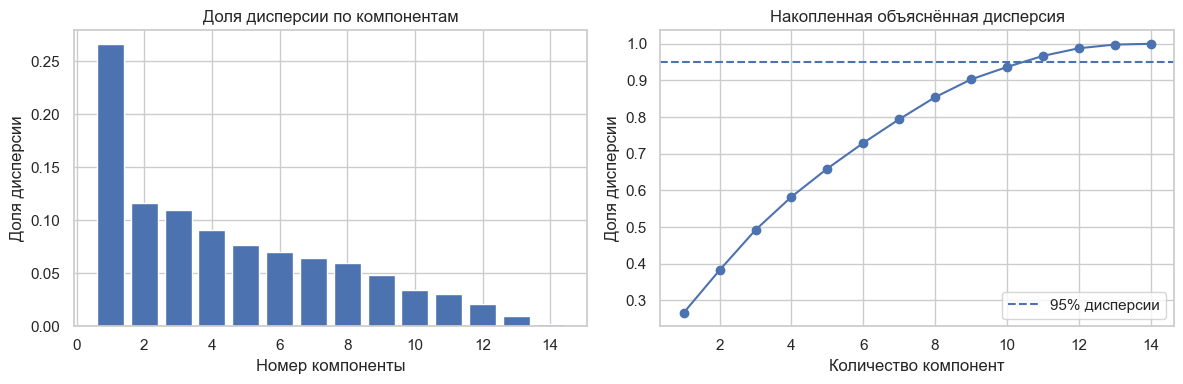

Компонент для объяснения 95% дисперсии: 11


In [11]:
pca = PCA().fit(X_train_scaled)
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(np.arange(1, len(explained_variance) + 1), explained_variance)
axes[0].set_title('Доля дисперсии по компонентам')
axes[0].set_xlabel('Номер компоненты')
axes[0].set_ylabel('Доля дисперсии')

axes[1].plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance, marker='o')
axes[1].axhline(0.95, linestyle='--', label='95% дисперсии')
axes[1].set_title('Накопленная объяснённая дисперсия')
axes[1].set_xlabel('Количество компонент')
axes[1].set_ylabel('Доля дисперсии')
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Компонент для объяснения 95% дисперсии: {(cumulative_variance < 0.95).sum() + 1}")

### Что означает результат PCA

Для объяснения 95% дисперсии потребовалось **11 из 14 компонент**. PCA не даёт радикально сократить размерность.

Более того, PCA осуществляет преобразование в пространстве признаков, поэтому теряется интерпретируемость каждого признака. 

Из-за скромного сокращения размерности и при этом необходимости жертвовать интерпертируемостью мною принято решение не прменять PCA далее.

Количество объектов по меткам DBSCAN (-1 означает шум):


,Количество объектов
Метка кластера,
-1,59
0,297
1,57


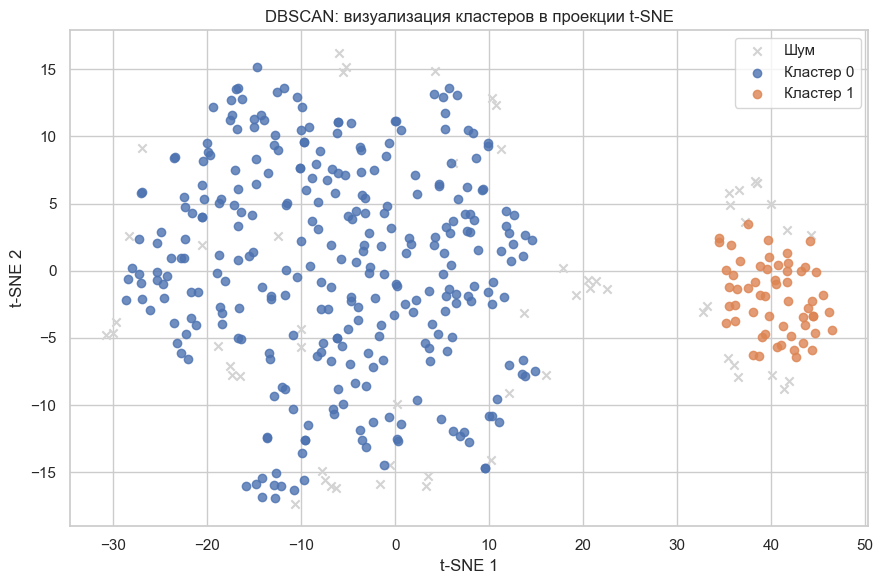

In [12]:
dbscan = DBSCAN(eps=2.5, min_samples=5)
cluster_labels = dbscan.fit_predict(X_train_scaled)
cluster_counts = pd.Series(cluster_labels, name='Метка кластера').value_counts().sort_index()
print('Количество объектов по меткам DBSCAN (-1 означает шум):')
display(cluster_counts.to_frame('Количество объектов'))

perplexity = min(30, len(X_train_scaled) - 1)
tsne = TSNE(
    n_components=2,
    perplexity=perplexity,
    random_state=RANDOM_STATE,
    init='pca',
    learning_rate='auto',
)
X_tsne = tsne.fit_transform(X_train_scaled)

plt.figure(figsize=(9, 6))
for label in np.unique(cluster_labels):
    mask = cluster_labels == label
    if label == -1:
        plt.scatter(X_tsne[mask, 0], X_tsne[mask, 1], c='lightgray', marker='x', label='Шум')
    else:
        plt.scatter(X_tsne[mask, 0], X_tsne[mask, 1], label=f'Кластер {label}', alpha=0.8)
plt.title('DBSCAN: визуализация кластеров в проекции t-SNE')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.legend()
plt.tight_layout()
plt.show()

DBSCAN дал 3 метки: **254 объекта в кластере 0, 50 — в кластере 1 и 57 объектов отнесены к шуму**. Это возможность пронаблюдать кластерную структуру в данных для парметров `eps=2.5` и `min_samples=5`, но это, конечно, не является доказателством того, что в природе существуют '3 типа пожара'. При других параметрах или масштабе данных структура может измениться.

## 5. Сравнение регрессионных моделей

В качестве ориентира используется `DummyRegressor`, который предсказывает среднее значение целевой переменной. С ним сравниваются линейные модели, методы на основе расстояний, многослойный перцептрон и ансамбли деревьев/градиентного бустинга.

Качество оценивается кросс-валидацией только на обучающей выборке. Основные метрики: `R²`, MAE и RMSE. Отрицательный `R²` означает, что на соответствующей выборке модель предсказывает хуже простого предсказания средним значением.

### Обоснование выбора данных метрик.

Метрика должна соответствовать цели прогноза и цене разных ошибок. В этой работе метрики отражают разные свойства модели:

| Метрика | Что измеряет | Почему полезна здесь | Ограничение |
|---|---|---|---|
| **\(R^2\)** | Насколько сумма квадратов ошибок меньше вариации относительно среднего на той же оценочной выборке | Основная метрика исследования: показывает, объясняют ли признаки вариацию `area` и превосходит ли модель простой ориентир |  Чувствительна к крупным ошибкам |
| **MAE** | Среднюю абсолютную ошибку в гектарах | Понятная средняя ошибка в единицах задачи. Штрафует линейно и меньше доминируется экстремумами, чем RMSE | Крупные ошибки в нашей задаче могут быть критичными, а эта метрика менее чувствительная к ним, чем RMSE или \(R^2\) |
| **RMSE** | Корень из средней квадратичной ошибки, тоже в гектарах | Сильнее штрафует большие промахи. Полезна, если ошибка на крупном пожаре намного дороже нескольких малых ошибок | Может в основном определяться несколькими экстремальными объектами |
| **Precision / Recall / F1** | Качество определения `area > 0` на первом этапе двухэтапной модели | Precision — доля правильных положительных прогнозов; Recall — доля найденных положительных случаев; F1 балансирует обе метрики | Зависит от порога вероятности и скрывает разные типы ошибок, если смотреть только F1 |

**Основной критерий ранжирования моделей — средний \(R^2\) на кросс-валидации**, поскольку одна из целей проекта — объяснить дисперсию площади пожара. Новажно учесть не только \(R^2\), нас интересует компромисс метрик.



In [13]:
def build_models():
    models = {
        'Dummy (среднее)': DummyRegressor(strategy='mean'),
        'Линейная регрессия': Pipeline([
            ('scaler', StandardScaler()),
            ('model', LinearRegression()),
        ]),
        'Ridge': Pipeline([
            ('scaler', StandardScaler()),
            ('model', Ridge(alpha=5.0)),
        ]),
        'Lasso': Pipeline([
            ('scaler', StandardScaler()),
            ('model', Lasso(alpha=0.1, max_iter=10000)),
        ]),
        'SVR (RBF)': Pipeline([
            ('scaler', StandardScaler()),
            ('model', SVR(kernel='rbf', C=2.0, epsilon=0.05)),
        ]),
        'KNN': Pipeline([
            ('scaler', StandardScaler()),
            ('model', KNeighborsRegressor(n_neighbors=20, weights='distance')),
        ]),
        'MLPRegressor': Pipeline([
            ('scaler', StandardScaler()),
            ('model', MLPRegressor(
                hidden_layer_sizes=(64, 32),
                alpha=0.01,
                max_iter=1000,
                early_stopping=True,
                random_state=RANDOM_STATE,
            )),
        ]),
        'Random Forest': RandomForestRegressor(
            n_estimators=200, max_depth=None, min_samples_leaf=2,
            random_state=RANDOM_STATE, n_jobs=1,
        ),
        'Extra Trees': ExtraTreesRegressor(
            n_estimators=200, min_samples_leaf=2,
            random_state=RANDOM_STATE, n_jobs=1,
        ),
    }

    if lgb is not None:
        models['LightGBM'] = lgb.LGBMRegressor(
            n_estimators=200, learning_rate=0.03, num_leaves=15,
            random_state=RANDOM_STATE, verbosity=-1, n_jobs=1,
        )
    if xgb is not None:
        models['XGBoost'] = xgb.XGBRegressor(
            n_estimators=200, max_depth=3, learning_rate=0.03,
            subsample=0.8, colsample_bytree=0.8,
            objective='reg:squarederror', random_state=RANDOM_STATE, n_jobs=1,
        )
    return models

models = build_models()
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'R2': 'r2',
    'MAE': 'neg_mean_absolute_error',
    'RMSE': 'neg_root_mean_squared_error',
}


In [14]:
cv_rows = []

for model_name, estimator in models.items():
    scores = cross_validate(
        estimator,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score='raise',
    )
    cv_rows.append({
        'Модель': model_name,
        'R² (среднее)': scores['test_R2'].mean(),
        'R² (std)': scores['test_R2'].std(),
        'MAE (среднее)': -scores['test_MAE'].mean(),
        'RMSE (среднее)': -scores['test_RMSE'].mean(),
    })

cv_results = pd.DataFrame(cv_rows).sort_values('R² (среднее)', ascending=False).reset_index(drop=True)
display(cv_results.round(4))

,Модель,R² (среднее),R² (std),MAE (среднее),RMSE (среднее)
0,MLPRegressor,-0.0236,0.0296,13.4557,39.5434
1,Dummy (среднее),-0.0299,0.0486,15.7306,39.6613
2,SVR (RBF),-0.0878,0.0499,11.1142,40.7024
3,KNN,-0.1235,0.1327,15.6016,40.5398
4,LightGBM,-0.2774,0.2623,17.8959,42.4766
5,Extra Trees,-0.3532,0.2708,18.2363,43.3541
6,Random Forest,-0.4651,0.4067,19.0360,44.7340
7,Lasso,-0.4689,0.7843,17.8296,42.9390
8,Ridge,-0.4958,0.8445,17.8350,43.0876
9,Линейная регрессия,-0.5280,0.8757,18.1029,43.3027


### Интерпретация кросс-валидации

Сохранённая таблица показывает, что лучший средний \(R^2\) в первом наборе экспериментов у `MLP`: **−0.0236**, стандартное отклонение 0.0296, MAE 13.4557 га и RMSE 39.5434 га. Эта модель перебила по \(R^2\) и RMSE все остальные, но по MAE уступает SVR с гауссовским ядром.


Большие стандартные отклонения \(R^2\) у MLP, KNN, Ridge/Lasso и ансамблей указывают на чувствительность к составу фолда -- в тех фолдах, в которых оказывается большое значение пожара у нас значение \(R^2\) очень сильно отличается, что увеличивает дисперсию оценки. 

`DummyRegressor(strategy='mean')` показывает, что получится без использования признаков. При кросс-валидации его \(R^2\) может быть отрицательным, потому что среднее оценивается на train-фолде, а качество — на другом фолде. Но мы видим, что он все же уступает регрессии с признаками.

## 6. Проверка выбранной модели на отложенной выборке

Модель выбирается по среднему `R²` на кросс-валидации обучающей выборки. Тестовые данные используются здесь только для итоговой оценки выбранного кандидата. Из-за маленького и асимметричного датасета результаты стоит интерпретировать осторожно.

,Выбранная модель,R² на test,MAE на test,RMSE на test
0,MLPRegressor,-0.0133,21.664,109.2932


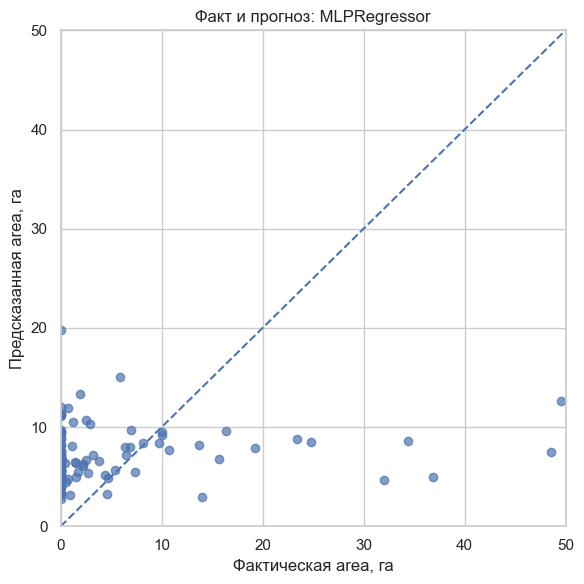

In [15]:
best_model_name = cv_results.loc[0, 'Модель']
best_model = clone(models[best_model_name])
best_model.fit(X_train, y_train)
y_pred_test = best_model.predict(X_test)

holdout_results = pd.DataFrame([{
    'Выбранная модель': best_model_name,
    'R² на test': r2_score(y_test, y_pred_test),
    'MAE на test': mean_absolute_error(y_test, y_pred_test),
    'RMSE на test': np.sqrt(mean_squared_error(y_test, y_pred_test)),
}])
display(holdout_results.round(4))

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_test, alpha=0.7)
upper = max(float(y_test.max()), float(np.max(y_pred_test)))
plt.plot([0, upper], [0, upper], linestyle='--')
plt.xlabel('Фактическая area, га')
plt.ylabel('Предсказанная area, га')
plt.title(f'Факт и прогноз: {best_model_name}')
plt.xlim(0, 50)
plt.ylim(0, 50)
plt.tight_layout()
plt.show()

### Результаты Теста
- Отрицательный \(R^2\), близкий к нулю, говорит, что на отложенной части MLP практически не объясняет вариацию площади и чуть проигрывает ориентиру по квадратам ошибок на этой выборке.
- MAE около 15 га описывает среднюю абсолютную ошибку. При медианной площади всей выборки всего 0,52 га это большая ошибка по отношению к типичному наблюдению.
- RMSE около 90 га значительно больше MAE. 

Все это обусловлено тем, что в тестовой выборки содержится наблюдение с огромным значением 'area'. И наша модель плохо его предсказала. 

Это говорит о том, что часть исследования посвященная решению такой задачи необходимо закончить, переходя к двухэтапному подходу.

## 7. Двухэтапная модель: классификация и регрессия

1. Сначала сравниваем несколько классификаторов для задачи `area > 0`.
2. Выбираем кандидата по кросс-валидации, настраиваем его гиперпараметры и калибруем вероятности.
3. Отдельно сравниваем регрессоры на подвыборке с `area > 0`, поскольку именно на ней определена целевая задача второй ступени.
4. Подбираем гиперпараметры условного регрессора.
5. Собираем двухэтапную модель, оцениваем её out-of-fold и проверяем на отложенной выборке.


### 7.1. Первая ступень: классификация `area > 0`

Создаём бинарную целевую переменную:

- `0` — площадь выгорания равна нулю;
- `1` — площадь выгорания положительная.

Для сравнения классификаторов используем StratifiedKFold: в каждом фолде сохраняется близкая доля классов. 
#### Почему нужны именно эти метрики

| Метрика | Для чего используем | Почему она важна здесь |
|---|---|---|
| **Average Precision (AP / PR-AUC)** | Основная метрика ранжирования классификаторов | Показывает, насколько хорошо модель поднимает реальные положительные наблюдения вверх в ранжировании. Для нашего прогнозирования факта пожара это важно |
| **ROC-AUC** | Дополнительная метрика ранжирования | Оценивает разделение классов при разных порогах. В нашем случае дислбаланса классов нет и она применима. |
| **Balanced Accuracy** | Выбор порога классификации | Усредняет полноту по обоим классам, поэтому не позволяет получить высокий результат, просто всегда предсказывая один класс. |
| **Precision / Recall / F1** | Анализ компромисса ошибок | Precision показывает долю верных положительных прогнозов; Recall — долю найденных положительных случаев; F1 объединяет их гармоническим средним. |
| **Brier score** | Проверка вероятностей | Измеряет средний квадрат ошибки вероятности. Нужен, потому что в мягком двухэтапном прогнозе вероятность будет умножаться на прогноз площади. Чем ниже Brier, тем лучше калибровка вероятностей. |


In [16]:
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import (
    ExtraTreesClassifier, HistGradientBoostingClassifier,
    RandomForestClassifier, ExtraTreesRegressor,
    HistGradientBoostingRegressor, RandomForestRegressor,
)
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    average_precision_score, balanced_accuracy_score, brier_score_loss,
    confusion_matrix, f1_score, mean_absolute_error, mean_squared_error,
    precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import (
    StratifiedKFold, KFold, cross_validate, cross_val_predict, GridSearchCV,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, SVR

# Создаём отдельные бинарные метки. Исходные y_train/y_test остаются площадью в гектарах.
y_train_fire = (y_train > 0).astype(int)
y_test_fire = (y_test > 0).astype(int)

class_distribution = pd.DataFrame({
    'Выборка': ['Train', 'Test'],
    'Всего наблюдений': [len(y_train_fire), len(y_test_fire)],
    'area = 0': [(y_train_fire == 0).sum(), (y_test_fire == 0).sum()],
    'area > 0': [(y_train_fire == 1).sum(), (y_test_fire == 1).sum()],
    'Доля area > 0': [y_train_fire.mean(), y_test_fire.mean()],
})
print(class_distribution.to_string(index=False, formatters={'Доля area > 0': '{:.1%}'.format}))

cv_class = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Выборка  Всего наблюдений  area = 0  area > 0 Доля area > 0
  Train               413       196       217         52.5%
   Test               104        51        53         51.0%


### 7.2. Сравнение классификаторов на одинаковых фолдах

Проверяем простую базовую модель и алгоритмы разных семейств: линейную модель, метод ближайших соседей, SVM и ансамбли деревьев. 
Гиперпараметры на этом шаге фиксированы и используются для первичного сравнения семейств моделей. После выбора кандидата будет отдельный этап настройки параметров.

In [17]:
classifiers = {
    'Dummy (prior)': DummyClassifier(strategy='prior'),
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(C=1.0, solver='liblinear', max_iter=3000,
                                     random_state=RANDOM_STATE)),
    ]),
    'Logistic Regression (balanced)': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(C=1.0, class_weight='balanced',
                                     solver='liblinear', max_iter=3000,
                                     random_state=RANDOM_STATE)),
    ]),
    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors=11, weights='distance')),
    ]),
    'SVC (RBF)': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVC(kernel='rbf', C=2.0, gamma='scale', probability=True,
                      random_state=RANDOM_STATE)),
    ]),
    'Random Forest': RandomForestClassifier(
        n_estimators=250, min_samples_leaf=3, max_features='sqrt',
        class_weight='balanced', random_state=RANDOM_STATE, n_jobs=1,
    ),
    'Extra Trees': ExtraTreesClassifier(
        n_estimators=250, min_samples_leaf=3, max_features='sqrt',
        class_weight='balanced', random_state=RANDOM_STATE, n_jobs=1,
    ),
    'HistGradientBoosting': HistGradientBoostingClassifier(
        max_iter=100, max_leaf_nodes=7, l2_regularization=1.0,
        random_state=RANDOM_STATE,
    ),
}

classification_scoring = {
    'AP': 'average_precision',
    'ROC_AUC': 'roc_auc',
    'Balanced_Accuracy': 'balanced_accuracy',
    'F1_at_0_5': 'f1',
    'Precision_at_0_5': 'precision',
    'Recall_at_0_5': 'recall',
    'Brier': 'neg_brier_score',
}

classification_rows = []
for model_name, estimator in classifiers.items():
    scores = cross_validate(
        estimator, X_train, y_train_fire,
        cv=cv_class, scoring=classification_scoring,
        n_jobs=1, error_score='raise',
    )
    classification_rows.append({
        'Модель': model_name,
        'AP (mean)': scores['test_AP'].mean(),
        'AP (std)': scores['test_AP'].std(ddof=1),
        'ROC-AUC': scores['test_ROC_AUC'].mean(),
        'Balanced Accuracy': scores['test_Balanced_Accuracy'].mean(),
        'F1 @ 0.5': scores['test_F1_at_0_5'].mean(),
        'Precision @ 0.5': scores['test_Precision_at_0_5'].mean(),
        'Recall @ 0.5': scores['test_Recall_at_0_5'].mean(),
        'Brier': -scores['test_Brier'].mean(),
    })

classification_results = (
    pd.DataFrame(classification_rows)
    .sort_values('AP (mean)', ascending=False)
    .reset_index(drop=True)
)
print(classification_results.round(4).to_string(index=False))
best_classifier_name = classification_results.loc[0, 'Модель']
print(f'\nКандидат с наибольшим средним AP: {best_classifier_name}')

                        Модель  AP (mean)  AP (std)  ROC-AUC  Balanced Accuracy  F1 @ 0.5  Precision @ 0.5  Recall @ 0.5  Brier
                     SVC (RBF)     0.5949    0.0564   0.5564             0.5340    0.5993           0.5531        0.6543 0.2545
          HistGradientBoosting     0.5877    0.0217   0.5396             0.4968    0.5304           0.5230        0.5396 0.2883
                 Random Forest     0.5841    0.0636   0.5420             0.5265    0.5740           0.5486        0.6042 0.2586
                   Extra Trees     0.5715    0.0470   0.5405             0.5356    0.5683           0.5572        0.5860 0.2524
                           KNN     0.5653    0.0602   0.5308             0.5417    0.6069           0.5632        0.6594 0.2767
Logistic Regression (balanced)     0.5579    0.0709   0.5196             0.5167    0.5448           0.5413        0.5485 0.2586
           Logistic Regression     0.5577    0.0712   0.5194             0.5085    0.5864           0.53

#### Интерпретация сравнения классификаторов

Лидирует **SVC с RBF-ядром**: средний AP около **0,595**, ROC-AUC около **0,556**. SVC поднимает качество ранжирования относительно случайного базового уровня.

С учётом цели первой ступени AP выбран как основной критерий ранжирования: нам важно, чтобы положительные случаи получали более высокие оценки вероятности. ROC-AUC, Balanced Accuracy, Precision/Recall и Brier остаются обязательными контрольными метриками.

In [18]:
svc_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE)),
])
svc_param_grid = {
    'model__C': [0.5, 2.0, 10.0],
    'model__gamma': ['scale', 0.1],
}
svc_search_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + 1)
svc_search = GridSearchCV(
    estimator=svc_pipeline,
    param_grid=svc_param_grid,
    scoring='average_precision',
    cv=svc_search_cv,
    n_jobs=1,
    refit=True,
)
svc_search.fit(X_train, y_train_fire)
print('Лучшие параметры SVC:', svc_search.best_params_)
print(f'Лучший средний AP внутри GridSearchCV: {svc_search.best_score_:.4f}')

Лучшие параметры SVC: {'model__C': 2.0, 'model__gamma': 0.1}
Лучший средний AP внутри GridSearchCV: 0.6254


### 7.3. Калибровка вероятностей и выбор порога

Для построения прогноза площади важны сами вероятности. Поэтому после настройки SVC применяем `CalibratedClassifierCV` с сигмоидальной калибровкой (`method='sigmoid'`). На небольших выборках она обычно менее склонна к переобучению, чем isotonic-калибровка.

Выбираем порог, максимизирующий **Balanced Accuracy** на out-of-fold вероятностях внутри обучающей выборки. Это компромисс между полнотой для обоих классов. 


In [19]:
calibrated_classifier_template = CalibratedClassifierCV(
    estimator=clone(svc_search.best_estimator_),
    method='sigmoid',
    cv=3,
)

oof_fire_probability = cross_val_predict(
    calibrated_classifier_template,
    X_train,
    y_train_fire,
    cv=cv_class,
    method='predict_proba',
    n_jobs=1,
)[:, 1]

fpr, tpr, thresholds = roc_curve(y_train_fire, oof_fire_probability)
balanced_accuracy_by_threshold = (tpr + (1 - fpr)) / 2
threshold_index = int(np.nanargmax(balanced_accuracy_by_threshold))
classification_threshold = float(thresholds[threshold_index])

# Brier для сравнения с простым прогнозом постоянной вероятностью класса.
oof_dummy_probability = cross_val_predict(
    DummyClassifier(strategy='prior'),
    X_train,
    y_train_fire,
    cv=cv_class,
    method='predict_proba',
    n_jobs=1,
)[:, 1]

print(f'OOF AP: {average_precision_score(y_train_fire, oof_fire_probability):.4f}')
print(f'OOF ROC-AUC: {roc_auc_score(y_train_fire, oof_fire_probability):.4f}')
print(f'OOF Brier выбранной модели: {brier_score_loss(y_train_fire, oof_fire_probability):.4f}')
print(f'OOF Brier Dummy: {brier_score_loss(y_train_fire, oof_dummy_probability):.4f}')
print(f'Порог по максимуму Balanced Accuracy: {classification_threshold:.4f}')
print(f'OOF Balanced Accuracy при выбранном пороге: {balanced_accuracy_score(y_train_fire, oof_fire_probability >= classification_threshold):.4f}')
print(f'OOF Precision / Recall / F1: '
      f'{precision_score(y_train_fire, oof_fire_probability >= classification_threshold):.4f} / '
      f'{recall_score(y_train_fire, oof_fire_probability >= classification_threshold):.4f} / '
      f'{f1_score(y_train_fire, oof_fire_probability >= classification_threshold):.4f}')

OOF AP: 0.5661
OOF ROC-AUC: 0.5453
OOF Brier выбранной модели: 0.2483
OOF Brier Dummy: 0.2494
Порог по максимуму Balanced Accuracy: 0.5152
OOF Balanced Accuracy при выбранном пороге: 0.5465
OOF Precision / Recall / F1: 0.5582 / 0.7512 / 0.6405


### 7.4. Вторая ступень: регрессия только для `area > 0`

Регрессор второй ступени обучается только на строках, где `y_train > 0`. 

Сравним базовый прогноз медианой, регуляризованную линейную модель, SVR и ансамбли деревьев. Для каждого семейства проверяем две постановки:

- исходная шкала `area`;
- логарифмическая шкала `log1p(area)` с автоматическим обратным преобразованием `expm1` через `TransformedTargetRegressor`.

Метрики R², MAE и RMSE рассчитываются после обратного преобразования, поэтому MAE и RMSE выражены в гектарах. Основной критерий отбора — средний R² на положительной части train.

In [20]:
positive_train_mask = y_train > 0
X_train_positive = X_train.loc[positive_train_mask]
y_train_positive = y_train.loc[positive_train_mask]

print(f'Положительных наблюдений для второй ступени: {len(y_train_positive)}')
print(f'Медиана положительной площади: {y_train_positive.median():.2f} га')
print(f'Средняя положительная площадь: {y_train_positive.mean():.2f} га')
print(f'Максимальная площадь в train: {y_train_positive.max():.2f} га')

regressor_candidates = {
    'Dummy (median)': DummyRegressor(strategy='median'),
    'Ridge': Pipeline([
        ('scaler', StandardScaler()),
        ('model', Ridge(alpha=10.0)),
    ]),
    'SVR (RBF)': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVR(kernel='rbf', C=10.0, epsilon=1.0)),
    ]),
    'Random Forest': RandomForestRegressor(
        n_estimators=250, min_samples_leaf=3, max_features=0.7,
        random_state=RANDOM_STATE, n_jobs=1,
    ),
    'Extra Trees': ExtraTreesRegressor(
        n_estimators=250, min_samples_leaf=3, max_features=0.7,
        random_state=RANDOM_STATE, n_jobs=1,
    ),
    'HistGradientBoosting': HistGradientBoostingRegressor(
        max_iter=100, max_leaf_nodes=7, l2_regularization=1.0,
        random_state=RANDOM_STATE,
    ),
}
cv_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
regression_rows = []

for scale_name in ['area', 'log1p(area)']:
    for model_name, base_estimator in regressor_candidates.items():
        if scale_name == 'log1p(area)':
            estimator = TransformedTargetRegressor(
                regressor=clone(base_estimator),
                func=np.log1p,
                inverse_func=np.expm1,
                check_inverse=False,
            )
        else:
            estimator = clone(base_estimator)

        scores = cross_validate(
            estimator,
            X_train_positive,
            y_train_positive,
            cv=cv_reg,
            scoring={
                'R2': 'r2',
                'MAE': 'neg_mean_absolute_error',
                'RMSE': 'neg_root_mean_squared_error',
            },
            n_jobs=1,
            error_score='raise',
        )
        regression_rows.append({
            'Модель': f'{model_name} ({scale_name})',
            'R² (mean)': scores['test_R2'].mean(),
            'R² (std)': scores['test_R2'].std(ddof=1),
            'MAE, га': -scores['test_MAE'].mean(),
            'RMSE, га': -scores['test_RMSE'].mean(),
        })

regression_results = (
    pd.DataFrame(regression_rows)
    .sort_values('R² (mean)', ascending=False)
    .reset_index(drop=True)
)
print(regression_results.round(4).to_string(index=False))
best_conditional_regressor_name = regression_results.loc[0, 'Модель']
print(f'\nЛучший кандидат по среднему R²: {best_conditional_regressor_name}')

Положительных наблюдений для второй ступени: 217
Медиана положительной площади: 6.30 га
Средняя положительная площадь: 21.19 га
Максимальная площадь в train: 746.28 га
                            Модель  R² (mean)  R² (std)  MAE, га  RMSE, га
               Ridge (log1p(area))    -0.0692    0.0245  18.7192   47.7488
       Random Forest (log1p(area))    -0.0815    0.0205  18.9948   47.8946
         Extra Trees (log1p(area))    -0.0826    0.0320  18.9302   47.9481
                  SVR (RBF) (area)    -0.1020    0.0226  19.0536   48.2055
             Dummy (median) (area)    -0.1124    0.0426  18.6090   48.2229
      Dummy (median) (log1p(area))    -0.1124    0.0426  18.6090   48.2229
           SVR (RBF) (log1p(area))    -0.1269    0.2479  20.5401   47.7345
HistGradientBoosting (log1p(area))    -0.1913    0.2091  20.1696   48.7387
                      Ridge (area)    -0.4815    0.7658  27.4096   49.9064
                Extra Trees (area)    -0.5632    0.9753  26.9058   50.3446
       

На текущем разбиении лучший результат по среднему R² показывает **Ridge с `log1p(area)`**.

По MAE Dummy немного лучше Ridge (примерно 18,61 против 18,72 га), тогда как по RMSE и R² Ridge немного выигрывает. То есть выбор Ridge основан на основном критерии R² и меньшей квадратичной ошибке, но модель не доминирует по всем метрикам.

Логарифмирование помогает смягчить влияние длинного правого хвоста при обучении. 

In [21]:
conditional_regressor_template = TransformedTargetRegressor(
    regressor=Pipeline([
        ('scaler', StandardScaler()),
        ('model', Ridge()),
    ]),
    func=np.log1p,
    inverse_func=np.expm1,
    check_inverse=False,
)
regressor_param_grid = {
    'regressor__model__alpha': [0.01, 0.1, 1.0, 10.0, 100.0, 500.0],
}
reg_search = GridSearchCV(
    estimator=conditional_regressor_template,
    param_grid=regressor_param_grid,
    scoring='r2',
    cv=cv_reg,
    n_jobs=1,
    refit=True,
)
reg_search.fit(X_train_positive, y_train_positive)
print('Лучшие параметры условного регрессора:', reg_search.best_params_)
print(f'Лучший средний CV R² на положительной части train: {reg_search.best_score_:.4f}')

Лучшие параметры условного регрессора: {'regressor__model__alpha': 0.01}
Лучший средний CV R² на положительной части train: -0.0603


Далее проверяем всю двухэтапную систему на пяти внешних фолдах train:

- внешний фолд остаётся вне обучения и настройки;
- внутри обучающей части фолда SVC подбирает `C` и `gamma` по AP;
- вероятности SVC калибруются методом sigmoid;
- Ridge подбирает `alpha` только на положительных объектах обучающей части фолда;
- на внешний фолд рассчитываются вероятность положительной площади и условный прогноз площади.

In [22]:
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
inner_classifier_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE + 1)
inner_regression_cv = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE + 2)

svc_param_grid_nested = {
    'model__C': [0.5, 2.0, 10.0],
    'model__gamma': ['scale', 0.1],
}
regressor_param_grid_nested = {
    'regressor__model__alpha': [0.01, 0.1, 1.0, 10.0, 100.0, 500.0],
}

oof_two_stage_probability = np.zeros(len(y_train), dtype=float)
oof_two_stage_conditional_area = np.zeros(len(y_train), dtype=float)

for fold, (fit_idx, valid_idx) in enumerate(outer_cv.split(X_train, y_train_fire), start=1):
    X_fit, X_valid = X_train.iloc[fit_idx], X_train.iloc[valid_idx]
    y_fit = y_train.iloc[fit_idx]
    y_fit_fire = (y_fit > 0).astype(int)

    # подбор SVC только внутри обучающей части внешнего фолда.
    fold_classifier_search = GridSearchCV(
        estimator=clone(svc_pipeline),
        param_grid=svc_param_grid_nested,
        scoring='average_precision',
        cv=inner_classifier_cv,
        n_jobs=1,
        refit=True,
    )
    fold_classifier_search.fit(X_fit, y_fit_fire)
    fold_calibrated_classifier = CalibratedClassifierCV(
        estimator=fold_classifier_search.best_estimator_,
        method='sigmoid',
        cv=3,
    )
    fold_calibrated_classifier.fit(X_fit, y_fit_fire)
    oof_two_stage_probability[valid_idx] = (
        fold_calibrated_classifier.predict_proba(X_valid)[:, 1]
    )

    # регрессор обучается только на положительных площадях внутри fit-фолда.
    fit_positive_mask = y_fit > 0
    fold_regressor_search = GridSearchCV(
        estimator=clone(conditional_regressor_template),
        param_grid=regressor_param_grid_nested,
        scoring='r2',
        cv=inner_regression_cv,
        n_jobs=1,
        refit=True,
    )
    fold_regressor_search.fit(
        X_fit.loc[fit_positive_mask],
        y_fit.loc[fit_positive_mask],
    )
    oof_two_stage_conditional_area[valid_idx] = np.maximum(
        fold_regressor_search.predict(X_valid), 0
    )

    print(
        f'Фолд {fold}: SVC {fold_classifier_search.best_params_}; '
        f'Ridge {fold_regressor_search.best_params_}'
    )

# Порог выбирается только по out-of-fold вероятностям обучающей выборки.
fpr_oof, tpr_oof, threshold_values_oof = roc_curve(
    y_train_fire, oof_two_stage_probability
)
balanced_accuracy_oof = (tpr_oof + (1 - fpr_oof)) / 2
optimal_two_stage_threshold = float(
    threshold_values_oof[int(np.nanargmax(balanced_accuracy_oof))]
)

oof_two_stage_soft = (
    oof_two_stage_probability * oof_two_stage_conditional_area
)
oof_two_stage_hard = np.where(
    oof_two_stage_probability >= optimal_two_stage_threshold,
    oof_two_stage_conditional_area,
    0.0,
)

print('\nКлассификация, out-of-fold:')
print(f'AP={average_precision_score(y_train_fire, oof_two_stage_probability):.4f}; '
      f'ROC-AUC={roc_auc_score(y_train_fire, oof_two_stage_probability):.4f}; '
      f'Brier={brier_score_loss(y_train_fire, oof_two_stage_probability):.4f}')
print(f'Порог={optimal_two_stage_threshold:.4f}; '
      f'Balanced Accuracy={balanced_accuracy_score(y_train_fire, oof_two_stage_probability >= optimal_two_stage_threshold):.4f}; '
      f'F1={f1_score(y_train_fire, oof_two_stage_probability >= optimal_two_stage_threshold):.4f}; '
      f'Precision={precision_score(y_train_fire, oof_two_stage_probability >= optimal_two_stage_threshold):.4f}; '
      f'Recall={recall_score(y_train_fire, oof_two_stage_probability >= optimal_two_stage_threshold):.4f}')

positive_train_array = y_train_fire.to_numpy().astype(bool)
print('\nУсловная регрессия только на положительных OOF-объектах:')
print(f'R²={r2_score(y_train.to_numpy()[positive_train_array], oof_two_stage_conditional_area[positive_train_array]):.4f}; '
      f'MAE={mean_absolute_error(y_train.to_numpy()[positive_train_array], oof_two_stage_conditional_area[positive_train_array]):.2f} га; '
      f'RMSE={np.sqrt(mean_squared_error(y_train.to_numpy()[positive_train_array], oof_two_stage_conditional_area[positive_train_array])):.2f} га')

print('\nВся двухэтапная система, out-of-fold:')
for label, prediction in [
    ('Мягкий прогноз', oof_two_stage_soft),
    ('Жёсткий порог', oof_two_stage_hard),
]:
    print(f'{label}: R²={r2_score(y_train, prediction):.4f}; '
          f'MAE={mean_absolute_error(y_train, prediction):.2f} га; '
          f'RMSE={np.sqrt(mean_squared_error(y_train, prediction)):.2f} га')

Фолд 1: SVC {'model__C': 2.0, 'model__gamma': 0.1}; Ridge {'regressor__model__alpha': 0.01}
Фолд 2: SVC {'model__C': 2.0, 'model__gamma': 0.1}; Ridge {'regressor__model__alpha': 500.0}
Фолд 3: SVC {'model__C': 2.0, 'model__gamma': 0.1}; Ridge {'regressor__model__alpha': 0.01}
Фолд 4: SVC {'model__C': 2.0, 'model__gamma': 0.1}; Ridge {'regressor__model__alpha': 500.0}
Фолд 5: SVC {'model__C': 2.0, 'model__gamma': 'scale'}; Ridge {'regressor__model__alpha': 500.0}

Классификация, out-of-fold:
AP=0.5688; ROC-AUC=0.5480; Brier=0.2480
Порог=0.5057; Balanced Accuracy=0.5487; F1=0.6727; Precision=0.5556; Recall=0.8525

Условная регрессия только на положительных OOF-объектах:
R²=-0.0512; MAE=18.81 га; RMSE=62.74 га

Вся двухэтапная система, out-of-fold:
Мягкий прогноз: R²=-0.0249; MAE=11.73 га; RMSE=46.17 га
Жёсткий порог: R²=-0.0112; MAE=12.71 га; RMSE=45.86 га


### 7.5. Оценка на Тесте

После CV фиксируем найденные параметры и обучаем обе ступени на всём `X_train`:

- классификатор — настроенный SVC с sigmoid-калибровкой вероятностей;
- регрессор — настроенный Ridge на `log1p(area)` только для положительных значений.


In [24]:
final_calibrated_classifier = CalibratedClassifierCV(
    estimator=clone(svc_search.best_estimator_),
    method='sigmoid',
    cv=3,
)
final_calibrated_classifier.fit(X_train, y_train_fire)
test_fire_probability = final_calibrated_classifier.predict_proba(X_test)[:, 1]
test_fire_prediction = (test_fire_probability >= optimal_two_stage_threshold).astype(int)

final_conditional_regressor = reg_search.best_estimator_
test_conditional_area = np.maximum(final_conditional_regressor.predict(X_test), 0)

test_prediction_soft = test_fire_probability * test_conditional_area
test_prediction_hard = np.where(
    test_fire_prediction == 1,
    test_conditional_area,
    0.0,
)

classification_test_metrics = pd.DataFrame([{
    'Порог': optimal_two_stage_threshold,
    'AP': average_precision_score(y_test_fire, test_fire_probability),
    'ROC-AUC': roc_auc_score(y_test_fire, test_fire_probability),
    'Brier': brier_score_loss(y_test_fire, test_fire_probability),
    'Balanced Accuracy': balanced_accuracy_score(y_test_fire, test_fire_prediction),
    'Precision': precision_score(y_test_fire, test_fire_prediction, zero_division=0),
    'Recall': recall_score(y_test_fire, test_fire_prediction, zero_division=0),
    'F1': f1_score(y_test_fire, test_fire_prediction, zero_division=0),
    'Предсказано area > 0': int(test_fire_prediction.sum()),
}])
print('Классификатор на test:')
print(classification_test_metrics.round(4).to_string(index=False))

cm = confusion_matrix(y_test_fire, test_fire_prediction, labels=[0, 1])
print('\nМатрица ошибок (строки — факт [0, 1], столбцы — прогноз [0, 1]):')
print(cm)

test_positive_mask = (y_test > 0).to_numpy()
y_test_positive = y_test.loc[y_test > 0]
predicted_positive_area = test_conditional_area[test_positive_mask]
conditional_test_metrics = pd.DataFrame([{
    'Наблюдений': len(y_test_positive),
    'R²': r2_score(y_test_positive, predicted_positive_area),
    'MAE, га': mean_absolute_error(y_test_positive, predicted_positive_area),
    'RMSE, га': np.sqrt(mean_squared_error(y_test_positive, predicted_positive_area)),
}])
print('\nУсловный регрессор только на положительной части test:')
print(conditional_test_metrics.round(4).to_string(index=False))

def regression_metrics_row(name, y_true, prediction):
    return {
        'Подход': name,
        'R²': r2_score(y_true, prediction),
        'MAE, га': mean_absolute_error(y_true, prediction),
        'RMSE, га': np.sqrt(mean_squared_error(y_true, prediction)),
    }

full_test_results = pd.DataFrame([
    regression_metrics_row('Прямая модель: MLP ', y_test, y_pred_test),
    regression_metrics_row('Двухэтапная: мягкое взвешивание вероятностью', y_test, test_prediction_soft),
    regression_metrics_row('Двухэтапная: жёсткий порог', y_test, test_prediction_hard),
])
print('\nСравнение полной регрессионной задачи на одной test-выборке:')
print(full_test_results.round(4).to_string(index=False))

largest_test_index = y_test.idxmax()
largest_test_position = y_test.index.get_loc(largest_test_index)
largest_case = pd.DataFrame([{
    'Индекс': largest_test_index,
    'Фактическая area, га': y_test.loc[largest_test_index],
    'P(area > 0)': test_fire_probability[largest_test_position],
    'Условный прогноз, га': test_conditional_area[largest_test_position],
    'Мягкий прогноз, га': test_prediction_soft[largest_test_position],
    'Жёсткий прогноз, га': test_prediction_hard[largest_test_position],
    'Прямой MLP, га': y_pred_test[largest_test_position],
}])
print('\nСамое крупное наблюдение в test:')
print(largest_case.round(4).to_string(index=False))

Классификатор на test:
 Порог     AP  ROC-AUC  Brier  Balanced Accuracy  Precision  Recall     F1  Предсказано area > 0
0.5057 0.6388   0.6071 0.2469             0.5603     0.5444  0.9245 0.6853                    90

Матрица ошибок (строки — факт [0, 1], столбцы — прогноз [0, 1]):
[[10 41]
 [ 4 49]]

Условный регрессор только на положительной части test:
 Наблюдений      R²  MAE, га  RMSE, га
         53 -0.0342  35.9527   152.206

Сравнение полной регрессионной задачи на одной test-выборке:
                                      Подход      R²  MAE, га  RMSE, га
                         Прямая модель: MLP  -0.0133  21.6640  109.2932
Двухэтапная: мягкое взвешивание вероятностью -0.0161  20.2286  109.4435
                  Двухэтапная: жёсткий порог -0.0039  21.1892  108.7819

Самое крупное наблюдение в test:
 Индекс  Фактическая area, га  P(area > 0)  Условный прогноз, га  Мягкий прогноз, га  Жёсткий прогноз, га  Прямой MLP, га
    238               1090.84       0.5385               1

#### Итоги

Я бы хотел отметить, что исходя из высокого значения recall и вида матрицы ошибок можно заключить, что модель находит почти все пожары, что критически важно в такой задаче. В то же время, она имеет большое число ложных срабатываний. Это, конечно, фактор негативный, но все же, Recall в этой задаче важнее.

Что касается регрессии, то качество по-прежнему невысокое. RMSE имеет аномально большие значения. Связано это в первую очередь с тестовым наблюдением с `area = 1 090,84` га. Наша модель просо не способна пресдкащать такие большие значения, так как такого рода данных довольно-таки мало в обучающей выборке. Модель не умеет экстраполировать редкие экстремальные события, и один такой промах резко увеличивает RMSE.

Двухэтапный подход дал прирост качества, но тем не менее, все еще показывает посредственный результат.